# Hidden Pressures on NSW Breeding Birds — Five Further Questions

**Purpose.** A second, separate set of analyses on the combined Atlas + DES breeding dataset. It looks for
patterns that the first client report (*Understanding Bird Breeding in NSW*) and the team's El Niño / rainfall
and breeding-timing work do not cover: **competition between birds, introduced species, which kinds of birds
are winning and losing, migrants, and the few places that hold breeding for the most species.**

Each section follows the same pattern:

> **Research question → How we measured it → Answer via visual → What it means**

| # | Research question | Angle |
|---|---|---|
| Q1 | Do small woodland birds breed less where **Noisy Miners** are present? | A native bully |
| Q2 | Which **introduced birds** are spreading across NSW, and which are retreating? | Invaders |
| Q3 | Which **native birds are winning and which are losing** ground, on a fair like-for-like comparison? | Winners and losers |
| Q4 | Are **migratory birds** that leave NSW each winter declining faster than birds that stay? | Threats beyond NSW |
| Q5 | How few places would protect **breeding for almost every species**, and are they still being watched? | Where to protect |

A client-ready PDF of the same results (no code) is written at the end of the notebook.

*Associations only — these results show patterns in the records, not proven causes.*

## 0. Settings you can customise
Change any value below and re-run the notebook (**Kernel → Restart & Run All**). Every number, chart and
sentence in the notebook and the PDF is recalculated from these settings.

In [1]:
from pathlib import Path
import textwrap, warnings, logging
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects
from matplotlib.patches import Rectangle
from matplotlib.backends.backend_pdf import PdfPages
from scipy.stats import binomtest, mannwhitneyu
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # Segoe UI falls back to Arial/Liberation off Windows

# ---------------- CUSTOMISE HERE ----------------
DATA_PATH = next(p for p in [Path("combined_atlas_des.parquet"), Path("../combined_atlas_des.parquet")] if p.exists())
OUTPUT_DIR = Path("outputs")                 # charts, tables and the PDF are saved here
PDF_NAME = "Hidden_Pressures_Report.pdf"
REPORT_TITLE = "Hidden Pressures on NSW Breeding Birds"
REPORT_SUBTITLE = "Five further questions from the Atlas and DES records"
PREPARED_FOR = "Client briefing"
PREPARED_BY = "CS-13 Combined Breeding Analysis team"

EARLY = (1977, 1999)            # historical period (Atlas)
RECENT = (2000, 2020)           # recent period (Atlas; Atlas ends March 2020)
MIN_LIST = 10                   # a survey counts as a "full list" if it records at least this many species

# Q1 - Noisy Miner comparison
NOISY_MINER = 634

# Q2-Q4 - fair (like-for-like) sampling of grid squares
FAIR_SHEETS = 5                 # survey sheets drawn per grid square in EACH period
FAIR_REPEATS = 25               # random draws averaged together
WARM_MONTHS = [9, 10, 11, 12, 1, 2, 3]   # Sep-Mar, when migrants are in NSW and most birds breed
MIN_OCCUPANCY = 10              # % of squares a species must reach in one period to be ranked (Q3, Q4)

# Q5 - priority breeding squares
COVER_TARGET = 0.90             # share of species whose breeding the chosen squares should include
RECENT_EVIDENCE = ((2000, 2020), (2021, 2025))   # Atlas years, DES years used as "recent breeding evidence"
# ------------------------------------------------

OUTPUT_DIR.mkdir(exist_ok=True)
print("Data file:", DATA_PATH.resolve())

Data file: /home/user/birdbreed/combined_atlas_des.parquet


In [2]:
# ---- Chart style (same colour-blind-safe palette as the first client report) ----
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8c8b86", "#e6e5e1", "#ffffff"
BLUE, ORANGE, RED, GREY_PT = "#2a78d6", "#eb6834", "#e34948", "#bdbcb6"
DARK_BLUE, LIGHT_BLUE, LIGHT_RED = "#184f95", "#86b6ef", "#f4a7a6"

mpl.rcParams.update({
    "font.family": ["Segoe UI", "Arial", "Liberation Sans", "DejaVu Sans"], "font.size": 9.5, "text.color": INK,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "pdf.fonttype": 42, "legend.frameon": False,
})
CHART_SIZE = (8.27, 5.4)        # same shape as the chart area on a PDF page
HALO = [mpl.patheffects.withStroke(linewidth=2.4, foreground="white")]

def headline(fig, title, subtitle):
    fig.text(0.07, 0.975, title, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    fig.text(0.07, 0.915, subtitle, ha="left", va="top", fontsize=9.5, color=INK2)

def show(chart, name):
    fig = plt.figure(figsize=CHART_SIZE)
    chart(fig)
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=200)
    plt.show()

def tidy_name(n):
    return n.title() if isinstance(n, str) and n.isupper() else n

def answer(Q):
    display(Markdown("### Answer\n" + "\n".join(f"* {f}" for f in Q["findings"]) +
                     f"\n\n**What it means:** {Q['meaning']}\n\n*Caution: {Q['caveat']}*"))

TOWNS = {"Sydney": (-33.87, 151.21), "Newcastle": (-32.93, 151.78), "Canberra": (-35.28, 149.13),
         "Dubbo": (-32.25, 148.60), "Broken Hill": (-31.95, 141.47), "Wagga Wagga": (-35.12, 147.37),
         "Armidale": (-30.51, 151.67), "Bourke": (-30.09, 145.94), "Griffith": (-34.29, 146.04),
         "Port Macquarie": (-31.43, 152.91), "Lismore": (-28.81, 153.28), "Albury": (-36.08, 146.92),
         "Bathurst": (-33.42, 149.58), "Tamworth": (-31.09, 150.93), "Moree": (-29.47, 149.84),
         "Wollongong": (-34.42, 150.89), "Nowra": (-34.88, 150.60), "Bega": (-36.67, 149.84),
         "Cooma": (-36.24, 149.12), "Goulburn": (-34.75, 149.72), "Orange": (-33.28, 149.10),
         "Mudgee": (-32.60, 149.59), "Coonabarabran": (-31.27, 149.28), "Narrabri": (-30.33, 149.78),
         "Grafton": (-29.69, 152.93), "Coffs Harbour": (-30.30, 153.11), "Taree": (-31.90, 152.46),
         "Forbes": (-33.38, 148.01), "Parkes": (-33.14, 148.17), "Cobar": (-31.50, 145.84),
         "Hay": (-34.51, 144.84), "Deniliquin": (-35.53, 144.96), "Narrandera": (-34.75, 146.55),
         "Young": (-34.31, 148.30), "Queanbeyan": (-35.35, 149.23), "Katoomba": (-33.71, 150.31),
         "Gosford": (-33.43, 151.34), "Maitland": (-32.73, 151.56), "Singleton": (-32.57, 151.17),
         "Muswellbrook": (-32.26, 150.89), "Glen Innes": (-29.74, 151.74), "Tenterfield": (-29.05, 152.02),
         "Inverell": (-29.77, 151.11), "Gunnedah": (-30.98, 150.25), "Walgett": (-30.02, 148.12),
         "Wilcannia": (-31.56, 143.38), "Ivanhoe": (-32.90, 144.30), "Balranald": (-34.64, 143.56),
         "Wentworth": (-34.11, 141.92), "Tibooburra": (-29.43, 142.01), "Nyngan": (-31.56, 147.19),
         "Lithgow": (-33.48, 150.16), "Batemans Bay": (-35.71, 150.18), "Eden": (-37.07, 149.90),
         "Tumut": (-35.30, 148.22), "Kempsey": (-31.08, 152.83), "Ballina": (-28.87, 153.56),
         "Leeton": (-34.55, 146.40), "Condobolin": (-33.09, 147.15), "West Wyalong": (-33.92, 147.21),
         "Warren": (-31.70, 147.83), "Coonamble": (-30.95, 148.39), "Brewarrina": (-29.96, 146.86),
         "Menindee": (-32.39, 142.42), "Jindabyne": (-36.42, 148.62), "Scone": (-32.05, 150.87)}

def nearest_town(lat, lon):
    k = min(TOWNS, key=lambda t: (TOWNS[t][0] - lat) ** 2 + ((TOWNS[t][1] - lon) * np.cos(np.radians(lat))) ** 2)
    dist = 111 * np.hypot(TOWNS[k][0] - lat, (TOWNS[k][1] - lon) * np.cos(np.radians(lat)))
    return k if dist < 15 else f"near {k}"

def nsw_axes(ax):
    ax.set_aspect(1 / np.cos(np.radians(33)))
    ax.set_xlim(140.8, 154); ax.set_ylim(-37.7, -28.0)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)

def label_towns(ax, towns, size=7.2):
    for t in towns:
        la, lo = TOWNS[t]
        ax.plot(lo, la, "o", ms=2.8, color=INK, zorder=5)
        ax.text(lo + 0.12, la + 0.08, t, fontsize=size, color=INK, zorder=5, path_effects=HALO)

## 1. Load and prepare the data
**What we keep.** Only rows marked `usable`, inside NSW. As in the first report, rates use **surveys only**
(collections are excluded) and Atlas and DES rates are never pooled.

**Full lists.** Many survey sheets record just one or two species. Q1–Q4 use only *full lists* — sheets with at
least 10 species — because a missing species on a full list is more meaningful.

**Why a "fair" comparison is needed.** Two things changed in the Atlas between 1977–1999 and 2000–2020:
* Early sheets were more often kept open for several months (13% vs 2%), so they collected more species.
* Recent lists in southern NSW are about a third shorter than early ones.

Both make almost every species look like it declined. So for Q2–Q4 we compare **like with like**: only
single-month full lists, and the **same number of sheets (5) in each grid square in each period**, drawn at
random and averaged over 25 draws. Each species' result is also compared with the **typical species**.

In [3]:
cols = ["source", "sheet_id", "species_id", "common_name", "breeding", "is_collection", "year", "month",
        "single_month", "klat", "klon", "region", "usable"]
raw = pd.read_parquet(DATA_PATH, columns=cols)
for c in ["source", "sheet_id", "common_name", "region"]:
    raw[c] = raw[c].astype("category")
data = raw[raw["usable"]].copy()
del raw

# Ten-minute grid codes are square centres (e.g. 3315 = 33 deg 15 min) -> decimal degrees
data["lat"] = -(data["klat"] // 100 + (data["klat"] % 100) / 60)
data["lon"] = data["klon"] // 100 + (data["klon"] % 100) / 60
data = data[data["lat"].between(-37.7, -28.0) & data["lon"].between(140.9, 153.7)]
data["square"] = (data["klat"].astype(int) * 100000 + data["klon"].astype(int))
names = data.drop_duplicates("species_id").set_index("species_id")["common_name"].astype(str).map(tidy_name)

atlas = data[(data["source"] == "Atlas") & ~data["is_collection"] & data["year"].between(EARLY[0], RECENT[1])].copy()
atlas["period"] = np.where(atlas["year"] <= EARLY[1], "early", "recent")
list_len = atlas.groupby("sheet_id", observed=True).size()
atlas["list_len"] = atlas["sheet_id"].map(list_len).astype(int)
full = atlas[atlas["list_len"] >= MIN_LIST]
sheets = full.drop_duplicates("sheet_id")[["sheet_id", "square", "period", "month", "single_month", "list_len", "lat", "lon"]]

summary = sheets.groupby("period").agg(full_lists=("sheet_id", "size"), squares=("square", "nunique"),
                                       median_species_per_list=("list_len", "median"),
                                       multi_month_share=("single_month", lambda s: 1 - s.astype(bool).mean()))
display(summary.style.format({"full_lists": "{:,.0f}", "squares": "{:,.0f}", "median_species_per_list": "{:.0f}",
                              "multi_month_share": "{:.0%}"}))

,full_lists,squares,median_species_per_list,multi_month_share
period,,,,
early,"81,154","2,854",32,17%
recent,"64,844","2,456",28,1%


In [4]:
def fair_occupancy(months=None):
    """Share of grid squares (%) where each species is recorded, drawing the same number of single-month
    full lists per square in each period, averaged over repeated random draws."""
    s = sheets[sheets["single_month"].astype(bool)]
    if months is not None:
        s = s[s["month"].isin(months)]
    n = s.groupby(["square", "period"]).size().unstack(fill_value=0)
    ok = n[(n["early"] >= FAIR_SHEETS) & (n["recent"] >= FAIR_SHEETS)].index
    s = s[s["square"].isin(ok)]
    rows = full[full["sheet_id"].isin(s["sheet_id"])][["sheet_id", "species_id", "square", "period"]]
    total = None
    for rep in range(FAIR_REPEATS):
        pick = s.sample(frac=1, random_state=rep)
        pick = pick[pick.groupby(["square", "period"]).cumcount() < FAIR_SHEETS]["sheet_id"]
        occ = (rows[rows["sheet_id"].isin(pick)].groupby(["species_id", "period"])["square"].nunique()
               .unstack(fill_value=0).reindex(columns=["early", "recent"], fill_value=0))
        total = occ if total is None else total.add(occ, fill_value=0)
    occ = total / FAIR_REPEATS / len(ok) * 100
    occ["name"] = names.reindex(occ.index)
    return occ, len(ok)

occ_all, n_sq_all = fair_occupancy()                 # all months (Q2)
occ_warm, n_sq_warm = fair_occupancy(WARM_MONTHS)   # Sep-Mar (Q3, Q4)
print(f"Fair comparison: {n_sq_all} grid squares (all months), {n_sq_warm} grid squares (Sep–Mar)")

Fair comparison: 1250 grid squares (all months), 870 grid squares (Sep–Mar)


---
## Q1. Do small woodland birds breed less where Noisy Miners are present?

**Why ask this.** The Noisy Miner is a native honeyeater that lives in groups and aggressively chases other
birds out of its territory. *Aggressive exclusion of small birds by Noisy Miners* is listed as a Key
Threatening Process in NSW. If the records show small birds breeding less on surveys where miners are present,
that supports controlling miners and restoring the dense shrub layer they avoid.

**How we measured it.**
* Compare full-list surveys **with** and **without** Noisy Miners that are otherwise alike: same ten-minute
  grid square, same period, and a similar number of other species on the list.
* For each small woodland bird (thornbills, robins, pardalotes, fairy-wrens, small honeyeaters, finches and
  similar) we measure (a) how often it is recorded and (b) when recorded, how often it is breeding.
* As a control, we do the same for **large birds** (magpies, ravens, cockatoos, butcherbirds) that miners
  cannot easily chase off. If miners matter, small birds should do worse and large birds should not.

In [5]:
SMALL = [481, 486, 470, 471, 475, 484, 476, 565, 976, 529, 536, 535, 377, 392, 380, 381, 385, 384, 382, 398,
         401, 361, 465, 453, 463, 454, 574, 583, 578, 613, 614, 625, 504, 466, 549, 564, 655, 652, 662, 369,
         365, 416, 591, 617]
LARGE = [705, 273, 322, 930, 694, 269, 700, 702, 415, 43, 424, 288, 638]

q1 = full.copy()
q1_sheets = q1.groupby("sheet_id", observed=True).agg(
    square=("square", "first"), period=("period", "first"),
    miner=("species_id", lambda s: (s == NOISY_MINER).any()), n=("species_id", "size"))
q1_sheets["others"] = q1_sheets["n"] - q1_sheets["miner"].astype(int)
q1_sheets = q1_sheets[q1_sheets["others"] >= MIN_LIST]
q1_sheets["length_band"] = pd.cut(q1_sheets["others"], [MIN_LIST - 1, 14, 19, 29, 39, 59, 999]).astype(str)
q1_sheets["stratum"] = (q1_sheets["square"].astype(str) + "|" + q1_sheets["period"] + "|" + q1_sheets["length_band"])
mix = q1_sheets.groupby("stratum")["miner"].agg(["mean", "size"])
matched = q1_sheets[q1_sheets["stratum"].isin(mix[(mix["mean"] > 0) & (mix["mean"] < 1)].index)]
eff = matched.groupby(["stratum", "miner"]).size().unstack().reindex(columns=[False, True], fill_value=0)

rec = q1[q1["sheet_id"].isin(matched.index) & q1["species_id"].isin(SMALL + LARGE)][["sheet_id", "species_id", "breeding"]]
rec = rec.join(matched[["stratum", "miner"]], on="sheet_id")

def mantel_haenszel(sp):
    # Stratified (matched) comparison of surveys with vs without miners
    x = rec[rec["species_id"] == sp]
    seen = x.groupby(["stratum", "miner"]).size().unstack().reindex(index=eff.index, columns=[False, True]).fillna(0)
    bred = (x[x["breeding"]].groupby(["stratum", "miner"]).size().unstack()
            .reindex(index=eff.index, columns=[False, True]).fillna(0))
    n1, n0 = eff[True], eff[False]; T = n1 + n0
    seen_ratio = (seen[True] * n0 / T).sum() / (seen[False] * n1 / T).sum()
    a1, b1 = bred[True], seen[True] - bred[True]
    a0, b0 = bred[False], seen[False] - bred[False]
    N = seen[True] + seen[False]; ok = N > 0
    breed_odds = (a1 * b0 / N)[ok].sum() / (b1 * a0 / N)[ok].sum()
    return pd.Series({"seen_ratio": seen_ratio, "breed_ratio": breed_odds,
                      "records": seen.values.sum(), "breeding_records": bred.values.sum()})

q1_res = pd.DataFrame({sp: mantel_haenszel(sp) for sp in SMALL + LARGE}).T
q1_res["name"] = names.reindex(q1_res.index)
q1_res["group"] = np.where(q1_res.index.isin(SMALL), "Small woodland birds", "Large birds (control)")
q1_res.to_csv(OUTPUT_DIR / "Q1_noisy_miner_by_species.csv")

small, large = q1_res[q1_res["group"] == "Small woodland birds"], q1_res[q1_res["group"] == "Large birds (control)"]
med = q1_res.groupby("group")[["seen_ratio", "breed_ratio"]].median()
n_small_lower = (small["breed_ratio"] < 1).sum()
sign_p = binomtest(n_small_lower, len(small), 0.5).pvalue
mw_p = mannwhitneyu(small["breed_ratio"], large["breed_ratio"]).pvalue

# How common are miners on full lists over time?
trend_sheets = q1_sheets.join(atlas.drop_duplicates("sheet_id").set_index("sheet_id")["year"])
trend_sheets["block"] = (trend_sheets["year"] // 5 * 5).astype(int)
miner_trend = trend_sheets[trend_sheets["block"] <= 2015].groupby("block")["miner"].mean() * 100

display(med.round(2))
print(f"Matched surveys: {len(matched):,} ({matched['miner'].mean():.0%} with miners) in {eff.shape[0]:,} matched groups")
print(f"{n_small_lower}/{len(small)} small species breed less with miners (sign test p = {sign_p:.1g}); "
      f"small vs large p = {mw_p:.1g}")

,seen_ratio,breed_ratio
group,,
Large birds (control),1.25,1.08
Small woodland birds,0.93,0.90


Matched surveys: 106,486 (49% with miners) in 6,416 matched groups
33/44 small species breed less with miners (sign test p = 0.001); small vs large p = 0.007


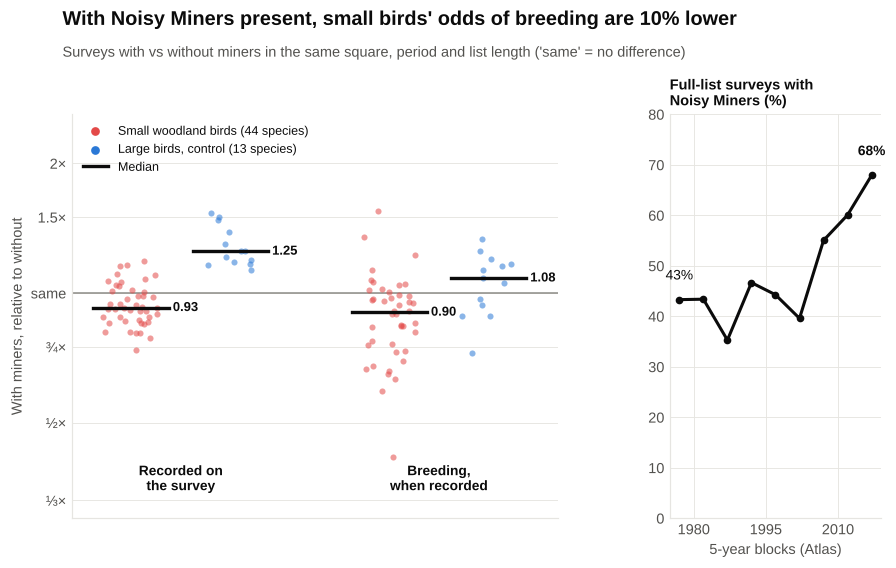

In [6]:
def chart_q1(fig):
    pct = (1 - med.loc["Small woodland birds", "breed_ratio"]) * 100
    headline(fig, f"With Noisy Miners present, small birds' odds of breeding are {pct:.0f}% lower",
             "Surveys with vs without miners in the same square, period and list length ('same' = no difference)")
    gs = fig.add_gridspec(1, 2, left=0.08, right=0.97, top=0.80, bottom=0.12, width_ratios=[2.3, 1], wspace=0.32)
    ax, bx = gs.subplots()
    rng = np.random.default_rng(3)
    groups = [("Small woodland birds", RED), ("Large birds (control)", BLUE)]
    for i, (metric, label) in enumerate([("seen_ratio", "Recorded on\nthe survey"), ("breed_ratio", "Breeding,\nwhen recorded")]):
        for j, (g, col) in enumerate(groups):
            x0 = i * 2.6 + j * 1.0
            v = q1_res.loc[q1_res["group"] == g, metric]
            ax.scatter(x0 + rng.uniform(-0.28, 0.28, len(v)), v, s=16, color=col, alpha=0.55, lw=0, zorder=2)
            m = v.median()
            ax.plot([x0 - 0.38, x0 + 0.38], [m, m], color=INK, lw=2.2, zorder=3)
            ax.text(x0 + 0.42, m, f"{m:.2f}", va="center", fontsize=8.5, fontweight="bold", path_effects=HALO)
        ax.text(i * 2.6 + 0.5, 0.06, label, ha="center", va="bottom", fontsize=9, fontweight="bold",
                transform=ax.get_xaxis_transform())
    ax.axhline(1, color=MUTED, lw=1, zorder=1)
    ax.set_yscale("log"); ax.set_ylim(0.3, 2.6)
    ax.set_yticks([0.33, 0.5, 0.75, 1, 1.5, 2], ["⅓×", "½×", "¾×", "same", "1.5×", "2×"]); ax.minorticks_off()
    ax.set_xticks([]); ax.set_xlim(-0.6, 4.3)
    ax.set_ylabel("With miners, relative to without")
    ax.scatter([], [], color=RED, s=22, label=f"Small woodland birds ({len(small)} species)")
    ax.scatter([], [], color=BLUE, s=22, label=f"Large birds, control ({len(large)} species)")
    ax.plot([], [], color=INK, lw=2.2, label="Median")
    ax.legend(loc="upper left", fontsize=8.2, ncol=1)
    bx.plot(miner_trend.index + 2, miner_trend.values, color=INK, lw=2, marker="o", ms=4)
    bx.set_ylim(0, max(80, miner_trend.max() * 1.15))
    bx.set_title("Full-list surveys with\nNoisy Miners (%)", loc="left", fontsize=9.5, fontweight="bold", pad=6)
    bx.set_xticks([1980, 1995, 2010], ["1980", "1995", "2010"])
    first, last = miner_trend.iloc[0], miner_trend.iloc[-1]
    bx.text(miner_trend.index[-1] + 2, last + 4, f"{last:.0f}%", ha="center", fontsize=9, fontweight="bold")
    bx.text(miner_trend.index[0] + 2, first + 4, f"{first:.0f}%", ha="center", fontsize=9)
    bx.set_xlabel("5-year blocks (Atlas)")

show(chart_q1, "Q1_noisy_miner")

In [7]:
worst = small[small["breeding_records"] >= 100].sort_values("breed_ratio").head(4)["name"].tolist()
Q1 = dict(
    question="Do small woodland birds breed less where Noisy Miners are present?",
    why="Noisy Miners live in groups and aggressively drive other birds from their territory; this is a listed "
        "Key Threatening Process in NSW. The records can show whether small birds breed less where miners are.",
    findings=[
        f"On otherwise-alike surveys, small woodland birds were recorded {(1 - med.loc['Small woodland birds', 'seen_ratio']):.0%} "
        f"less often when miners were present, while large birds were recorded "
        f"{(med.loc['Large birds (control)', 'seen_ratio'] - 1):.0%} more often.",
        f"When small birds were recorded alongside miners, the odds that they were breeding were about "
        f"{(1 - med.loc['Small woodland birds', 'breed_ratio']):.0%} lower. {n_small_lower} of {len(small)} small species "
        f"showed lower breeding; large birds showed no such drop (median {med.loc['Large birds (control)', 'breed_ratio']:.2f}).",
        f"Among species with at least 100 breeding records, the biggest breeding gaps were for "
        f"{', '.join(worst[:-1])} and {worst[-1]}.",
        f"Miners became more common: they were on {miner_trend.iloc[0]:.0f}% of full-list surveys in "
        f"{miner_trend.index[0]}–{miner_trend.index[0] + 4} and {miner_trend.iloc[-1]:.0f}% in "
        f"{miner_trend.index[-1]}–{miner_trend.index[-1] + 4}.",
    ],
    meaning="The pattern matches the known impact of Noisy Miners on small birds. Restoring a dense shrub layer, "
            "and miner control in high-value woodland remnants, could lift breeding of many small species at once.",
    caveat="Miners prefer open, fragmented woodland, and that habitat may itself suit small birds less. The matching "
           "removes place and time differences but cannot fully separate the miners from the habitat they choose.",
)
answer(Q1)

### Answer
* On otherwise-alike surveys, small woodland birds were recorded 7% less often when miners were present, while large birds were recorded 25% more often.
* When small birds were recorded alongside miners, the odds that they were breeding were about 10% lower. 33 of 44 small species showed lower breeding; large birds showed no such drop (median 1.08).
* Among species with at least 100 breeding records, the biggest breeding gaps were for Flame Robin, Eastern Yellow Robin, White-eared Honeyeater and Crested Shrike-tit.
* Miners became more common: they were on 43% of full-list surveys in 1975–1979 and 68% in 2015–2019.

**What it means:** The pattern matches the known impact of Noisy Miners on small birds. Restoring a dense shrub layer, and miner control in high-value woodland remnants, could lift breeding of many small species at once.

*Caution: Miners prefer open, fragmented woodland, and that habitat may itself suit small birds less. The matching removes place and time differences but cannot fully separate the miners from the habitat they choose.*

---
## Q2. Which introduced birds are spreading across NSW, and which are retreating?

**Why ask this.** Introduced birds compete with native birds for food and nest sites. The Common Myna in
particular takes over tree hollows that native parrots, kingfishers and small mammals need. Knowing which
introduced species are spreading, and in which direction, shows where control would prevent new invasions.

**How we measured it.**
* The **fair comparison** (same number of single-month full lists per grid square in each period) gives the
  share of grid squares in which each introduced bird was recorded, 1977–1999 vs 2000–2020.
* The typical native species is shown for reference, because shorter recent lists lower everyone's numbers.
* The map shows where Common Mynas were recorded in each period, using all surveys in squares visited in both.

In [8]:
INTRODUCED = {998: "Common Myna", 999: "Common Starling", 995: "House Sparrow", 989: "Spotted Dove",
              991: "Common Blackbird", 957: "Rock Dove", 996: "European Goldfinch", 990: "Red-whiskered Bulbul"}
intro = occ_all.reindex(list(INTRODUCED)).copy()
intro["name"] = [INTRODUCED[i] for i in intro.index]
intro["change"] = intro["recent"] - intro["early"]
intro["rel_change"] = intro["recent"] / intro["early"] - 1
native_all = occ_all.drop(list(INTRODUCED), errors="ignore")
native_all = native_all[native_all[["early", "recent"]].max(axis=1) >= MIN_OCCUPANCY]
typical_native = (native_all["recent"] / native_all["early"] - 1).median()
intro = intro.sort_values("rel_change")
intro.round(2).to_csv(OUTPUT_DIR / "Q2_introduced_species.csv")

# Myna map: squares visited at least 5 times in each period (any survey)
sq_n = atlas.drop_duplicates("sheet_id").groupby(["square", "period"]).size().unstack(fill_value=0)
both_sq = sq_n[(sq_n["early"] >= 5) & (sq_n["recent"] >= 5)].index
myna = atlas[(atlas["species_id"] == 998) & atlas["square"].isin(both_sq)]
myna_sq = myna.groupby("square")["period"].agg(lambda s: "both" if s.nunique() == 2 else s.iat[0])
sq_xy = atlas.drop_duplicates("square").set_index("square")[["lat", "lon"]]
myna_map = sq_xy.reindex(myna_sq.index).assign(status=myna_sq)
grid_bg = sq_xy.reindex(both_sq)
n_new, n_lost, n_kept = (myna_sq == "recent").sum(), (myna_sq == "early").sum(), (myna_sq == "both").sum()
myna_west = (myna_map["lon"] < 150.0)
west_early = myna_map[myna_map["status"].isin(["early", "both"]) & myna_west].shape[0]
west_recent = myna_map[myna_map["status"].isin(["recent", "both"]) & myna_west].shape[0]
bred_sq = atlas[atlas["species_id"].isin(INTRODUCED) & atlas["breeding"] & atlas["square"].isin(both_sq)]
bred_sq = bred_sq.groupby(["species_id", "period"])["square"].nunique().unstack(fill_value=0)
bred_sq.index = [INTRODUCED[i] for i in bred_sq.index]
display(intro[["name", "early", "recent", "rel_change"]].round(2))
display(bred_sq)
print(f"Typical native species: {typical_native:+.0%}. Myna squares: {n_kept} both, {n_new} new, {n_lost} lost; "
      f"west of 150°E: {west_early} -> {west_recent}")

period,name,early,recent,rel_change
species_id,,,,
996,European Goldfinch,18.55,8.93,-0.52
995,House Sparrow,58.44,40.19,-0.31
999,Common Starling,81.85,66.12,-0.19
957,Rock Dove,21.38,17.72,-0.17
990,Red-whiskered Bulbul,2.99,2.79,-0.07
989,Spotted Dove,12.86,15.33,0.19
991,Common Blackbird,14.84,19.48,0.31
998,Common Myna,10.21,23.87,1.34


period,early,recent
Rock Dove,57,31
Spotted Dove,69,52
Red-whiskered Bulbul,24,11
Common Blackbird,82,38
House Sparrow,319,109
European Goldfinch,105,14
Common Myna,64,77
Common Starling,504,169


Typical native species: -13%. Myna squares: 229 both, 314 new, 26 lost; west of 150°E: 36 -> 144


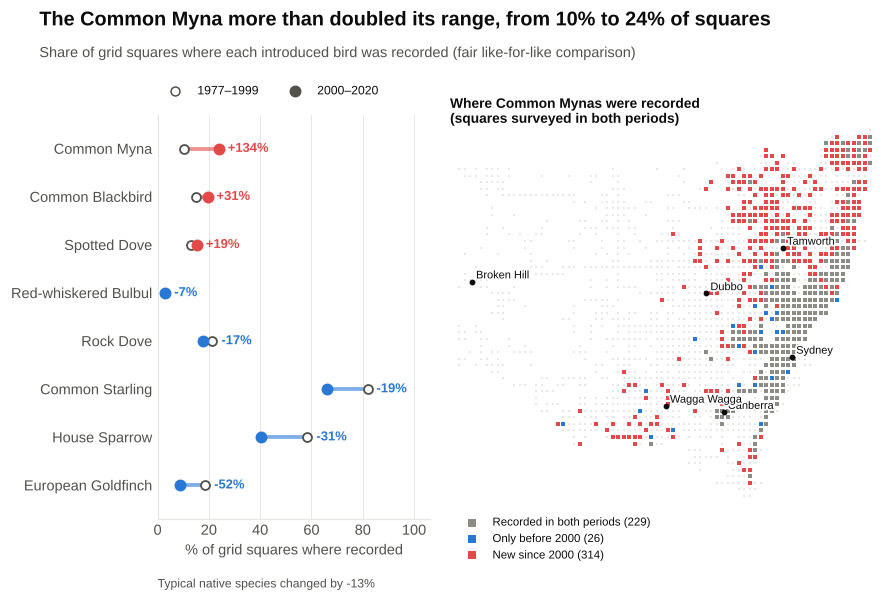

In [9]:
def chart_q2(fig):
    m = intro.loc[998]
    headline(fig, f"The Common Myna more than doubled its range, from {m['early']:.0f}% to {m['recent']:.0f}% of squares",
             "Share of grid squares where each introduced bird was recorded (fair like-for-like comparison)")
    ax = fig.add_gridspec(1, 1, left=0.20, right=0.50, top=0.80, bottom=0.12).subplots()
    mx = fig.add_axes([0.52, 0.14, 0.48, 0.64])
    y = np.arange(len(intro))
    for i, (_, r) in enumerate(intro.iterrows()):
        up = r["recent"] > r["early"]
        col = RED if up else BLUE
        ax.plot([r["early"], r["recent"]], [i, i], color=col, lw=2.5, alpha=0.6, zorder=2, solid_capstyle="round")
        ax.scatter(r["early"], i, s=34, color="white", edgecolor=INK2, lw=1.2, zorder=3)
        ax.scatter(r["recent"], i, s=46, color=col, zorder=4)
        ax.text(max(r["early"], r["recent"]) + 3.5, i, f"{r['rel_change']:+.0%}", va="center", fontsize=8.5,
                color=col, fontweight="bold")
    ax.set_yticks(y, intro["name"]); ax.set_ylim(-0.7, len(intro) - 0.3)
    ax.set_xlim(0, max(intro[["early", "recent"]].max()) * 1.3)
    ax.set_xlabel("% of grid squares where recorded")
    ax.grid(axis="y", visible=False)
    ax.scatter([], [], s=34, color="white", edgecolor=INK2, label=f"{EARLY[0]}–{EARLY[1]}")
    ax.scatter([], [], s=46, color=INK2, label=f"{RECENT[0]}–{RECENT[1]}")
    ax.legend(loc="upper left", fontsize=8, ncol=2, bbox_to_anchor=(-0.02, 1.10))
    ax.text(0.0, -0.17, f"Typical native species changed by {typical_native:+.0%}", transform=ax.transAxes,
            fontsize=8, color=INK2)
    mx.scatter(grid_bg["lon"], grid_bg["lat"], s=2.5, marker="s", color="#e9e8e4", lw=0, zorder=0)
    style = {"both": (MUTED, "Recorded in both periods"), "early": (BLUE, "Only before 2000"),
             "recent": (RED, "New since 2000")}
    for k in ["both", "early", "recent"]:
        p = myna_map[myna_map["status"] == k]
        mx.scatter(p["lon"], p["lat"], s=6, marker="s", color=style[k][0], lw=0, zorder=2,
                   label=f"{style[k][1]} ({len(p)})")
    nsw_axes(mx)
    label_towns(mx, ["Sydney", "Canberra", "Dubbo", "Tamworth", "Wagga Wagga", "Broken Hill"])
    mx.set_title("Where Common Mynas were recorded\n(squares surveyed in both periods)", loc="left", fontsize=9,
                 fontweight="bold", pad=2)
    mx.legend(loc="upper left", fontsize=7.5, markerscale=2.2, bbox_to_anchor=(0.0, 0.0), ncol=1)

show(chart_q2, "Q2_introduced_species")

In [10]:
retreat = intro[intro["rel_change"] < typical_native].sort_values("rel_change")
gainers = intro[(intro["rel_change"] > 0) & (intro.index != 998)].sort_values("rel_change", ascending=False)
Q2 = dict(
    question="Which introduced birds are spreading across NSW, and which are retreating?",
    why="Introduced birds compete with natives for food and nest sites. The Common Myna in particular takes over "
        "tree hollows that native parrots, kingfishers and gliders need. Knowing what is spreading shows where "
        "control could stop new invasions.",
    findings=[
        f"On a fair like-for-like comparison, the Common Myna went from {intro.loc[998, 'early']:.0f}% to "
        f"{intro.loc[998, 'recent']:.0f}% of grid squares ({intro.loc[998, 'rel_change']:+.0%}), while the typical "
        f"native bird changed by {typical_native:+.0%}.",
        f"The Myna appeared in {n_new} new squares and disappeared from only {n_lost}. West of the Great Dividing "
        f"Range (west of 150°E) its squares went from {west_early} to {west_recent}, so it is moving inland along "
        f"towns and farmland.",
        f"{' and '.join(gainers['name'])} gained more modestly "
        f"({', '.join(f'{v:+.0%}' for v in gainers['rel_change'])}). {', '.join(retreat['name'].head(4))} "
        f"retreated faster than the typical native bird.",
        f"Breeding records of House Sparrows and Common Starlings fell from {bred_sq.loc['House Sparrow', 'early']} "
        f"and {bred_sq.loc['Common Starling', 'early']} squares to {bred_sq.loc['House Sparrow', 'recent']} and "
        f"{bred_sq.loc['Common Starling', 'recent']}, while the Myna bred in {bred_sq.loc['Common Myna', 'early']} "
        f"then {bred_sq.loc['Common Myna', 'recent']} squares.",
    ],
    meaning="The Common Myna is the introduced bird to act on. Trapping and nest-box programmes are most useful at "
            "the inland edge of its range, before it settles in new towns and competes for hollows.",
    caveat="Introduced birds live mostly near people, and volunteer surveys visit towns unevenly; the like-for-like "
           "comparison reduces but does not remove this effect.",
)
answer(Q2)

### Answer
* On a fair like-for-like comparison, the Common Myna went from 10% to 24% of grid squares (+134%), while the typical native bird changed by -13%.
* The Myna appeared in 314 new squares and disappeared from only 26. West of the Great Dividing Range (west of 150°E) its squares went from 36 to 144, so it is moving inland along towns and farmland.
* Common Blackbird and Spotted Dove gained more modestly (+31%, +19%). European Goldfinch, House Sparrow, Common Starling, Rock Dove retreated faster than the typical native bird.
* Breeding records of House Sparrows and Common Starlings fell from 319 and 504 squares to 109 and 169, while the Myna bred in 64 then 77 squares.

**What it means:** The Common Myna is the introduced bird to act on. Trapping and nest-box programmes are most useful at the inland edge of its range, before it settles in new towns and competes for hollows.

*Caution: Introduced birds live mostly near people, and volunteer surveys visit towns unevenly; the like-for-like comparison reduces but does not remove this effect.*

---
## Q3. Which native birds are winning and which are losing ground, on a fair like-for-like comparison?

**Why ask this.** A list of individual declines is useful, but the *kinds* of birds that win and lose say more
about what is changing in the landscape. If the same kinds of birds keep turning up among the losers, they
probably share a pressure that can be managed for all of them together.

**How we measured it.** The fair comparison in the warm half of the year (September–March, when most birds
breed and migrants are present): the share of grid squares in which each native species is recorded,
1977–1999 vs 2000–2020. Each species' change is shown **relative to the typical species**, so 0 means "changed
the same as most birds". Only species recorded in at least 10% of squares in one period are ranked.

In [11]:
SPLIT_NAMES = [291, 294]     # Mallee/Australian Ringneck: a naming change between periods, not a real change
# Bird groups used in Q3 and Q4 (from general knowledge of each species' diet and movements)
MIGRANTS = [329, 318, 326, 324, 347, 348, 337, 338, 339, 342, 344, 341, 359, 360, 547, 545, 544, 430, 509, 508,
            365, 366, 362, 373, 375, 671, 453, 429, 524]          # breed in NSW, leave for winter
RESIDENT_INSECT = [369, 377, 364, 361, 385, 381, 392, 380, 549, 416, 555, 558, 560, 529, 536, 535, 486, 484, 475,
                   470, 471, 481, 465, 466, 504, 408, 398, 415, 647, 357, 358, 546, 488, 421, 976, 565, 443, 445,
                   675, 693]                                       # stay all year, mainly eat insects
INSECT_EATERS = set(MIGRANTS) - {347, 348, 671} | set(RESIDENT_INSECT)   # koel, channel-bill, oriole eat mainly fruit
PARROTS = [254, 256, 258, 260, 267, 268, 269, 270, 271, 272, 273, 274, 277, 280, 281, 282, 286, 288, 295, 296, 297,
           302, 310]
q3 = occ_warm.drop(list(INTRODUCED) + SPLIT_NAMES, errors="ignore")
q3 = q3[q3[["early", "recent"]].max(axis=1) >= MIN_OCCUPANCY].copy()
q3["rel"] = q3["recent"] / q3["early"]
TYPICAL_Q3 = q3["rel"].median()
q3["vs_typical"] = (q3["rel"] / TYPICAL_Q3 - 1) * 100
q3 = q3.sort_values("vs_typical")
q3.round(2).to_csv(OUTPUT_DIR / "Q3_native_winners_losers.csv")

N_SHOW = 12
losers, winners = q3.head(N_SHOW), q3.tail(N_SHOW)
n_down_big = (q3["vs_typical"] <= -25).sum()
n_up_big = (q3["vs_typical"] >= 25).sum()
loser_insect = losers.index.isin(INSECT_EATERS).sum()
winner_insect = winners.index.isin(INSECT_EATERS).sum()
winner_parrot = winners.index.isin(PARROTS).sum()
few_winners = "none" if winner_insect == 0 else f"only {winner_insect}"
print(f"{len(q3)} native species ranked; typical change {TYPICAL_Q3 - 1:+.0%}; "
      f"{n_down_big} at least 25% worse than typical, {n_up_big} at least 25% better")
display(pd.concat([losers, winners])[["name", "early", "recent", "vs_typical"]].round(1))

194 native species ranked; typical change -10%; 24 at least 25% worse than typical, 14 at least 25% better


period,name,early,recent,vs_typical
species_id,,,,
546,Black-faced Woodswallow,14.2,5.1,-59.8
358,White-backed Swallow,10.4,3.9,-57.6
385,Hooded Robin,19.9,8.7,-51.2
225,Little Eagle,30.1,15.0,-44.6
380,Scarlet Robin,16.9,8.7,-42.5
560,Red-browed Treecreeper,10.3,5.4,-42.3
648,Horsfield's Bushlark,10.6,5.6,-41.7
466,Southern Whiteface,20.8,11.3,-39.7
416,Crested Shrike-tit,31.3,18.3,-35.0


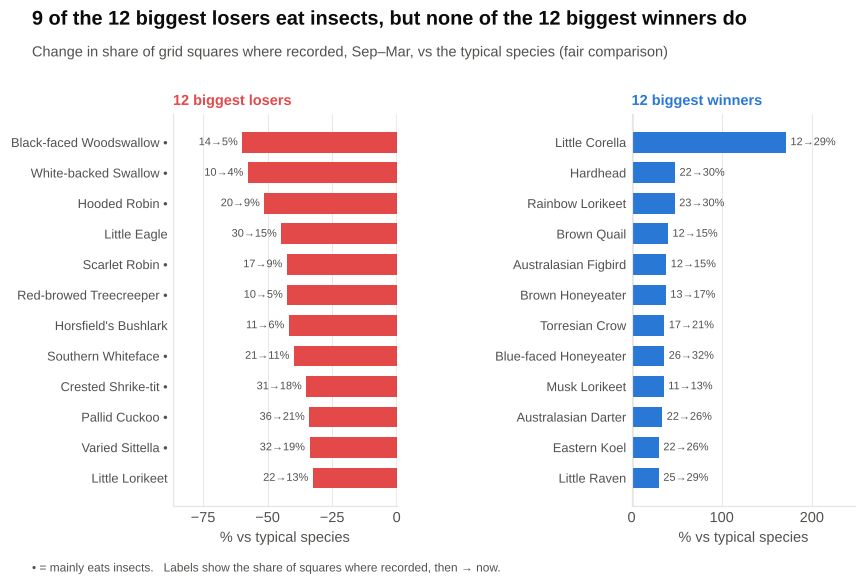

In [12]:
def chart_q3(fig):
    headline(fig, f"{loser_insect} of the {N_SHOW} biggest losers eat insects, but {few_winners} of the "
                  f"{N_SHOW} biggest winners do",
             "Change in share of grid squares where recorded, Sep–Mar, vs the typical species (fair comparison)")
    gs = fig.add_gridspec(1, 2, left=0.225, right=0.975, top=0.80, bottom=0.14, wspace=1.05)
    for ax, part, col, title in [(gs[0], losers, RED, f"{N_SHOW} biggest losers"),
                                 (gs[1], winners.iloc[::-1], BLUE, f"{N_SHOW} biggest winners")]:
        ax = fig.add_subplot(ax)
        y = np.arange(len(part))[::-1]
        ax.barh(y, part["vs_typical"], color=col, height=0.68)
        labels = [n + (" •" if i in INSECT_EATERS else "") for i, n in zip(part.index, part["name"])]
        ax.set_yticks(y, labels, fontsize=8.4)
        ax.axvline(0, color=INK2, lw=0.8)
        span = part["vs_typical"].abs().max()
        for yi, v, e, r in zip(y, part["vs_typical"], part["early"], part["recent"]):
            ax.text(v + (0.03 if v > 0 else -0.03) * span, yi, f"{e:.0f}→{r:.0f}%", va="center",
                    ha="left" if v > 0 else "right", fontsize=7.2, color=INK2)
        ax.set_xlim((-span * 1.45, 0) if col == RED else (0, span * 1.45))
        ax.locator_params(axis="x", nbins=4)
        ax.set_title(title, loc="left", fontsize=9.5, fontweight="bold", color=col)
        ax.grid(axis="y", visible=False)
        ax.set_xlabel("% vs typical species")
    fig.text(0.07, 0.03, "• = mainly eats insects.   Labels show the share of squares where recorded, "
             "then → now.", fontsize=7.8, color=INK2)

show(chart_q3, "Q3_native_winners_losers")

In [13]:
Q3 = dict(
    question="Which native birds are winning and which are losing ground, on a fair like-for-like comparison?",
    why="The kinds of birds that win and lose say more about what is changing in the landscape than any single "
        "species. Losers that share a way of life probably share a pressure that can be managed together.",
    findings=[
        f"Of {len(q3)} widespread native species, {n_down_big} lost at least 25% more ground than the typical "
        f"species and {n_up_big} gained at least 25% more.",
        f"The biggest losers are {', '.join(losers['name'].head(6))}. {loser_insect} of the {N_SHOW} biggest losers "
        f"mainly eat insects, most of them birds of open woodland and grassland.",
        f"The biggest winners are {', '.join(winners['name'].iloc[::-1].head(6))}. {few_winners.capitalize()} of the "
        f"{N_SHOW} biggest winners mainly eat insects. They are a mix of {winner_parrot} parrots and lorikeets, "
        f"water birds, and fruit- and nectar-eaters common in gardens and towns.",
        "Together this points to insect-eating woodland birds giving way to more adaptable species.",
    ],
    meaning="Protecting and restoring open woodland with native grasses, fallen timber and insect-rich ground layers "
            "would help the largest group of losers at once. Q4 looks at whether migrants are a special case.",
    caveat="'Winning' and 'losing' here mean recorded in more or fewer places, not the number of birds. Shorter recent "
           "lists lower all species, which is why results are compared with the typical species.",
)
answer(Q3)

### Answer
* Of 194 widespread native species, 24 lost at least 25% more ground than the typical species and 14 gained at least 25% more.
* The biggest losers are Black-faced Woodswallow, White-backed Swallow, Hooded Robin, Little Eagle, Scarlet Robin, Red-browed Treecreeper. 9 of the 12 biggest losers mainly eat insects, most of them birds of open woodland and grassland.
* The biggest winners are Little Corella, Hardhead, Rainbow Lorikeet, Brown Quail, Australasian Figbird, Brown Honeyeater. None of the 12 biggest winners mainly eat insects. They are a mix of 3 parrots and lorikeets, water birds, and fruit- and nectar-eaters common in gardens and towns.
* Together this points to insect-eating woodland birds giving way to more adaptable species.

**What it means:** Protecting and restoring open woodland with native grasses, fallen timber and insect-rich ground layers would help the largest group of losers at once. Q4 looks at whether migrants are a special case.

*Caution: 'Winning' and 'losing' here mean recorded in more or fewer places, not the number of birds. Shorter recent lists lower all species, which is why results are compared with the typical species.*

---
## Q4. Are migratory birds that leave NSW each winter declining faster than birds that stay?

**Why ask this.** Many NSW birds arrive in spring to breed and spend winter in northern Australia, New Guinea
or Indonesia. If migrants are declining faster than birds that stay all year, part of the problem lies outside
NSW, on their migration routes or wintering grounds. That changes who needs to act.

**How we measured it.** The same fair warm-season comparison as Q3. Species are grouped as:
* **Summer migrants** — breed in NSW and leave for winter (bee-eaters, cuckoos, woodswallows, martins,
  songlarks, trillers, monarchs, Dollarbird, Sacred Kingfisher and others).
* **Resident insect-eaters** — stay all year and also eat insects (robins, thornbills, fairy-wrens, treecreepers,
  flycatchers and others). This group checks that any difference is not simply about eating insects.
* **Other residents.**

In [14]:
# MIGRANTS and RESIDENT_INSECT are defined in Q3
q4 = occ_warm.drop(list(INTRODUCED) + SPLIT_NAMES, errors="ignore")
q4 = q4[q4[["early", "recent"]].max(axis=1) >= MIN_OCCUPANCY].copy()
q4["vs_typical"] = (q4["recent"] / q4["early"] / TYPICAL_Q3 - 1) * 100
q4["group"] = np.select([q4.index.isin(MIGRANTS), q4.index.isin(RESIDENT_INSECT)],
                        ["Summer migrants", "Resident insect-eaters"], "Other residents")
GROUP_ORDER = ["Summer migrants", "Resident insect-eaters", "Other residents"]
q4.round(2).to_csv(OUTPUT_DIR / "Q4_migrants_vs_residents.csv")

g4 = q4.groupby("group")["vs_typical"].agg(["median", "size"]).reindex(GROUP_ORDER)
g4["share_worse"] = q4.groupby("group")["vs_typical"].apply(lambda v: (v < 0).mean()).reindex(GROUP_ORDER) * 100
mig = q4[q4["group"] == "Summer migrants"]
p_mig_res = mannwhitneyu(mig["vs_typical"], q4[q4["group"] == "Other residents"]["vs_typical"]).pvalue
p_mig_ins = mannwhitneyu(mig["vs_typical"], q4[q4["group"] == "Resident insect-eaters"]["vs_typical"]).pvalue
display(g4.round(1))
print(f"Migrants vs other residents p = {p_mig_res:.2g}; migrants vs resident insect-eaters p = {p_mig_ins:.2g}")

,median,size,share_worse
group,,,
Summer migrants,-8.2,24,79.2
Resident insect-eaters,-6.1,39,53.8
Other residents,3.5,131,43.5


Migrants vs other residents p = 0.001; migrants vs resident insect-eaters p = 0.69


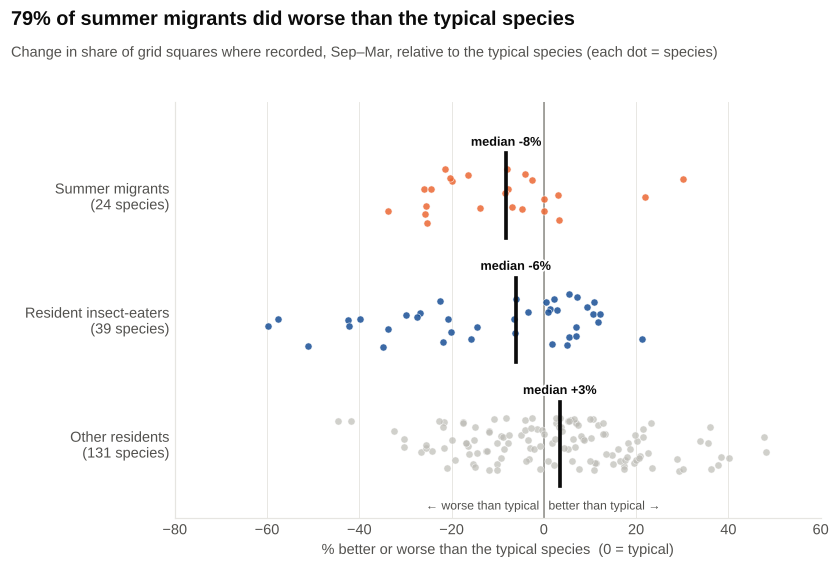

In [15]:
def chart_q4(fig):
    headline(fig, f"{g4.loc['Summer migrants', 'share_worse']:.0f}% of summer migrants did worse than the typical "
                  f"species",
             "Change in share of grid squares where recorded, Sep–Mar, relative to the typical species (each dot = species)")
    ax = fig.add_gridspec(1, 1, left=0.25, right=0.96, top=0.82, bottom=0.12).subplots()
    rng = np.random.default_rng(7)
    cols = {"Summer migrants": ORANGE, "Resident insect-eaters": DARK_BLUE, "Other residents": GREY_PT}
    for i, g in enumerate(GROUP_ORDER):
        v = q4[q4["group"] == g]
        y = len(GROUP_ORDER) - 1 - i
        ax.scatter(v["vs_typical"], y + rng.uniform(-0.22, 0.22, len(v)), s=22, color=cols[g],
                   alpha=0.85 if g != "Other residents" else 0.7, lw=0.4, edgecolor="white", zorder=2)
        m = g4.loc[g, "median"]
        ax.plot([m, m], [y - 0.34, y + 0.34], color=INK, lw=2.4, zorder=3)
        ax.text(m, y + 0.38, f"median {m:+.0f}%", ha="center", va="bottom", fontsize=8.3, fontweight="bold",
                path_effects=HALO, zorder=4)
    ax.axvline(0, color=MUTED, lw=1, zorder=1)
    ax.text(1, -0.55, "better than typical →", fontsize=8, color=INK2, va="bottom")
    ax.text(-1, -0.55, "← worse than typical", fontsize=8, color=INK2, va="bottom", ha="right")
    ax.set_yticks(range(3), [f"{g}\n({g4.loc[g, 'size']:.0f} species)" for g in GROUP_ORDER[::-1]])
    ax.set_ylim(-0.6, 2.75)
    lo, hi = q4["vs_typical"].quantile([0.005, 0.995])
    ax.set_xlim(min(-80, lo - 5), max(60, hi + 5))
    ax.set_xlabel("% better or worse than the typical species  (0 = typical)")
    ax.grid(axis="y", visible=False)

show(chart_q4, "Q4_migrants_vs_residents")

In [16]:
Q4 = dict(
    question="Are migratory birds that leave NSW each winter declining faster than birds that stay?",
    why="If birds that winter in northern Australia or New Guinea are declining faster than those that stay, part "
        "of the cause lies outside NSW — on migration routes or wintering grounds — and needs action beyond NSW.",
    findings=[
        f"Summer migrants lost more ground than other birds: median {g4.loc['Summer migrants', 'median']:+.0f}% "
        f"against the typical species, versus {g4.loc['Other residents', 'median']:+.0f}% for other residents "
        f"(difference unlikely to be chance, p = {p_mig_res:.1g}).",
        f"{g4.loc['Summer migrants', 'share_worse']:.0f}% of the {g4.loc['Summer migrants', 'size']:.0f} migrant species "
        f"did worse than typical, compared with {g4.loc['Other residents', 'share_worse']:.0f}% of other residents.",
        (f"Resident insect-eaters also slipped (median {g4.loc['Resident insect-eaters', 'median']:+.0f}%), and the gap "
         f"between them and migrants is not clear (p = {p_mig_ins:.1g}). The decline is shared by insect-eaters in "
         f"general, with migrants the worst affected." if p_mig_ins >= 0.05 else
         f"Migrants also did worse than resident insect-eaters (median {g4.loc['Resident insect-eaters', 'median']:+.0f}%, "
         f"p = {p_mig_ins:.1g}), so eating insects alone does not explain it."),
        f"The steepest migrant losses were {', '.join(mig.nsmallest(4, 'vs_typical')['name'])}.",
    ],
    meaning="Insect-eating birds, and summer migrants most of all, are the groups to watch. Possible pressures include "
            "fewer insects in farmland and woodland in NSW, and, for migrants, conditions on their routes and "
            "wintering grounds. The migrant results are worth sharing with national migratory-bird programmes.",
    caveat="The migrant list is based on general knowledge of each species' movements; some species are only partly "
           "migratory. The comparison cannot say where along the journey the pressure lies.",
)
answer(Q4)

### Answer
* Summer migrants lost more ground than other birds: median -8% against the typical species, versus +3% for other residents (difference unlikely to be chance, p = 0.001).
* 79% of the 24 migrant species did worse than typical, compared with 44% of other residents.
* Resident insect-eaters also slipped (median -6%), and the gap between them and migrants is not clear (p = 0.7). The decline is shared by insect-eaters in general, with migrants the worst affected.
* The steepest migrant losses were Pallid Cuckoo, Brown Songlark, White-browed Woodswallow, Tree Martin.

**What it means:** Insect-eating birds, and summer migrants most of all, are the groups to watch. Possible pressures include fewer insects in farmland and woodland in NSW, and, for migrants, conditions on their routes and wintering grounds. The migrant results are worth sharing with national migratory-bird programmes.

*Caution: The migrant list is based on general knowledge of each species' movements; some species are only partly migratory. The comparison cannot say where along the journey the pressure lies.*

---
## Q5. How few places would protect breeding for almost every species, and are they still being watched?

**Why ask this.** Protection budgets are limited. Some places hold breeding for many species at once; others
hold the only recent breeding of a rare bird. Choosing places that **complement** each other gives the most
species for the fewest sites.

**How we measured it.**
* *Recent breeding evidence:* any breeding record (survey or collection) in the Atlas 2000–2020 or DES
  2021–2025, by ten-minute grid square (about 18 × 15 km). Introduced species are excluded.
* We pick squares one at a time, each time choosing the square that adds the most species not yet covered
  (a standard "complementarity" method used in reserve planning).
* We then check how many of the chosen squares had any survey in 2021–2025.

In [17]:
(a0, a1), (d0, d1) = RECENT_EVIDENCE
ev = data[(((data["source"] == "Atlas") & data["year"].between(a0, a1)) |
           ((data["source"] == "DES") & data["year"].between(d0, d1))) & data["breeding"]
          & ~data["species_id"].isin(list(INTRODUCED) + [298])]   # 298: unmatched DES code (see data notes)
sp_squares = ev.groupby("species_id")["square"].apply(set)
sq_species = {}
for sp, sqs in sp_squares.items():
    for q in sqs:
        sq_species.setdefault(q, set()).add(sp)

remaining, chosen, cum = set(sp_squares.index), [], []
while remaining:
    best = max(sq_species, key=lambda q: len(sq_species[q] & remaining))
    gain = sq_species[best] & remaining
    chosen.append((best, len(gain), len(sq_species[best])))
    remaining -= gain
    cum.append(len(sp_squares) - len(remaining))
pick = pd.DataFrame(chosen, columns=["square", "new_species", "species_breeding"])
pick["cum_share"] = np.array(cum) / len(sp_squares)
pick["rank"] = np.arange(1, len(pick) + 1)
xy = data.drop_duplicates("square").set_index("square")[["lat", "lon"]]
pick = pick.join(xy, on="square")
pick["place"] = [nearest_town(la, lo) for la, lo in zip(pick["lat"], pick["lon"])]

recent_survey_sq = set(data[(data["year"] >= 2021) & ~data["is_collection"]]["square"])
pick["surveyed_2021_25"] = pick["square"].isin(recent_survey_sq)
n_target = int((pick["cum_share"] < COVER_TARGET).sum() + 1)
n_half = int((pick["cum_share"] < 0.5).sum() + 1)
target = pick.head(n_target)
n_sp_squares = sp_squares.map(len)
single = n_sp_squares[n_sp_squares == 1]
all_breed_sq = xy.reindex(list(sq_species))
pick.to_csv(OUTPUT_DIR / "Q5_priority_squares.csv", index=False)
pd.DataFrame({"species": names.reindex(single.index),
              "square": [next(iter(sp_squares[s])) for s in single.index]}).to_csv(
    OUTPUT_DIR / "Q5_single_square_species.csv")

display(target[["rank", "place", "new_species", "species_breeding", "cum_share", "surveyed_2021_25"]].head(15))
print(f"{len(sp_squares)} native species with recent breeding evidence in {len(sq_species)} squares. "
      f"{n_half} squares cover 50%, {n_target} cover {COVER_TARGET:.0%}, {len(pick)} cover all. "
      f"{len(single)} species bred in only one square. "
      f"{target['surveyed_2021_25'].sum()} of the {n_target} priority squares were surveyed in 2021–2025.")

,rank,place,new_species,species_breeding,cum_share,surveyed_2021_25
0,1,near Gosford,122,122,0.327957,True
1,2,near Moree,52,103,0.467742,True
2,3,near Kempsey,32,116,0.553763,True
3,4,near Lithgow,24,66,0.618280,True
4,5,near Batemans Bay,11,99,0.647849,True
5,6,near Ivanhoe,9,46,0.672043,False
6,7,near Port Macquarie,8,95,0.693548,True
7,8,near Tibooburra,7,13,0.712366,False
8,9,near Wentworth,6,14,0.728495,True
9,10,near Moree,5,89,0.741935,True


372 native species with recent breeding evidence in 1566 squares. 3 squares cover 50%, 32 cover 90%, 68 cover all. 39 species bred in only one square. 22 of the 32 priority squares were surveyed in 2021–2025.


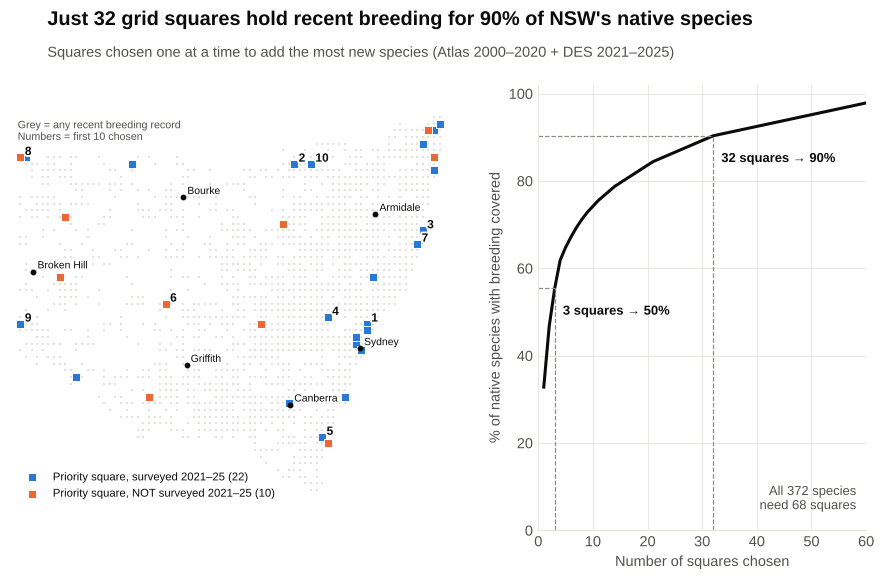

In [18]:
def chart_q5(fig):
    headline(fig, f"Just {n_target} grid squares hold recent breeding for {COVER_TARGET:.0%} of NSW's native species",
             "Squares chosen one at a time to add the most new species (Atlas 2000–2020 + DES 2021–2025)")
    gs = fig.add_gridspec(1, 2, left=0.03, right=0.97, top=0.85, bottom=0.10, width_ratios=[1.35, 1], wspace=0.22)
    mx, cx = gs.subplots()
    mx.scatter(all_breed_sq["lon"], all_breed_sq["lat"], s=3, marker="s", color="#e2e1dc", lw=0, zorder=0)
    unw = target[~target["surveyed_2021_25"]]
    wat = target[target["surveyed_2021_25"]]
    mx.scatter(wat["lon"], wat["lat"], s=30, marker="s", color=BLUE, lw=0.6, edgecolor="white", zorder=3,
               label=f"Priority square, surveyed 2021–25 ({len(wat)})")
    mx.scatter(unw["lon"], unw["lat"], s=30, marker="s", color=ORANGE, lw=0.6, edgecolor="white", zorder=3,
               label=f"Priority square, NOT surveyed 2021–25 ({len(unw)})")
    for _, r in target.head(10).iterrows():
        mx.text(r["lon"] + 0.13, r["lat"] + 0.05, str(r["rank"]), fontsize=7.8, fontweight="bold", color=INK,
                zorder=4, path_effects=HALO)
    nsw_axes(mx)
    label_towns(mx, ["Sydney", "Canberra", "Broken Hill", "Bourke", "Griffith", "Armidale"], size=6.8)
    mx.legend(loc="lower left", fontsize=7.4, bbox_to_anchor=(0.0, -0.02))
    mx.text(141.0, -28.15, "Grey = any recent breeding record\nNumbers = first 10 chosen", fontsize=7, color=INK2,
            va="top")
    n_show = min(len(pick), max(n_target + 15, 60))
    cx.plot(pick["rank"].head(n_show), pick["cum_share"].head(n_show) * 100, color=INK, lw=2)
    for k, lab in [(n_half, "50%"), (n_target, f"{COVER_TARGET:.0%}")]:
        v = pick.loc[k - 1, "cum_share"] * 100
        cx.plot([k, k], [0, v], color=MUTED, lw=0.8, ls="--"); cx.plot([0, k], [v, v], color=MUTED, lw=0.8, ls="--")
        cx.text(k + 1.5, v - 6, f"{k} squares → {lab}", fontsize=8.5, fontweight="bold")
    cx.set_xlim(0, n_show); cx.set_ylim(0, 102)
    cx.set_xlabel("Number of squares chosen"); cx.set_ylabel("% of native species with breeding covered")
    cx.text(n_show * 0.97, 4, f"All {len(sp_squares)} species\nneed {len(pick)} squares", ha="right", va="bottom",
            fontsize=8.5, color=INK2)

show(chart_q5, "Q5_priority_squares")

In [19]:
top3 = ", ".join(f"{r['place']} ({r['species_breeding']} species)" for _, r in pick.head(3).iterrows())
Q5 = dict(
    question="How few places would protect breeding for almost every species, and are they still being watched?",
    why="Protection budgets are limited. Picking places that complement each other — each adding species the "
        "others lack — protects the most breeding species for the fewest sites.",
    findings=[
        f"{len(sp_squares)} native species have recent breeding evidence, spread over {len(sq_species):,} grid squares.",
        f"Just {n_half} squares hold breeding for half of these species, and {n_target} squares hold {COVER_TARGET:.0%}. "
        f"The first three chosen are {top3}.",
        f"{len(single)} species have recent breeding evidence from only one square, so a single local loss could "
        f"remove them as breeders from the records (listed in the accompanying table).",
        f"Only {target['surveyed_2021_25'].sum()} of the {n_target} priority squares had any survey in 2021–2025; "
        f"{(~target['surveyed_2021_25']).sum()} have gone unwatched in recent years.",
    ],
    meaning=f"The {n_target} priority squares are a short, practical list for protection checks and for repeat "
            "surveys. The unwatched priority squares should be the first places sent new volunteers.",
    caveat="Squares rich in species are also often the most surveyed, so some may rank highly partly because they "
           "were watched more closely. Species recorded breeding in only one square may simply be under-surveyed.",
)
answer(Q5)

### Answer
* 372 native species have recent breeding evidence, spread over 1,566 grid squares.
* Just 3 squares hold breeding for half of these species, and 32 squares hold 90%. The first three chosen are near Gosford (122 species), near Moree (103 species), near Kempsey (116 species).
* 39 species have recent breeding evidence from only one square, so a single local loss could remove them as breeders from the records (listed in the accompanying table).
* Only 22 of the 32 priority squares had any survey in 2021–2025; 10 have gone unwatched in recent years.

**What it means:** The 32 priority squares are a short, practical list for protection checks and for repeat surveys. The unwatched priority squares should be the first places sent new volunteers.

*Caution: Squares rich in species are also often the most surveyed, so some may rank highly partly because they were watched more closely. Species recorded breeding in only one square may simply be under-surveyed.*

---
## Summary — what this means for protecting bird species

In [20]:
SUMMARY = [
    ("Noisy Miners", f"Where miners are present, small woodland birds are recorded "
                     f"{(1 - med.loc['Small woodland birds', 'seen_ratio']):.0%} less often and their odds of breeding "
                     f"are {(1 - med.loc['Small woodland birds', 'breed_ratio']):.0%} lower; large birds are unaffected."),
    ("Introduced birds", f"The Common Myna went from {intro.loc[998, 'early']:.0f}% to {intro.loc[998, 'recent']:.0f}% of "
                         f"squares and is moving inland; sparrows, starlings and goldfinches retreated."),
    ("Winners and losers", f"{loser_insect} of the {N_SHOW} native birds that lost most ground eat insects, such as "
                           f"{losers['name'].iloc[0]} and {losers['name'].iloc[2]}; {few_winners} of the {N_SHOW} "
                           f"biggest winners do."),
    ("Migrants", f"{g4.loc['Summer migrants', 'share_worse']:.0f}% of summer migrants did worse than typical, against "
                 f"{g4.loc['Other residents', 'share_worse']:.0f}% of non-insect-eating residents; insect-eaters "
                 f"that stay all year also slipped."),
    ("Where to protect", f"{n_target} grid squares hold recent breeding for {COVER_TARGET:.0%} of native species; "
                         f"{(~target['surveyed_2021_25']).sum()} of them had no survey in 2021–2025."),
]
NEXT_STEPS = [
    "Trial miner management and shrub-layer planting in woodland remnants, with before-and-after nest surveys.",
    "Focus Common Myna trapping on the inland edge of its range, before it settles in new towns.",
    "Brief the managers of open woodland and native grassland on the insect-eating birds losing ground.",
    "Share the migrant results with national and international migratory-bird programmes.",
    f"Send volunteers first to the {(~target['surveyed_2021_25']).sum()} unwatched priority squares, and check the "
    f"single-square breeders on the ground.",
]
display(Markdown("\n".join(f"* **{k}:** {v}" for k, v in SUMMARY) + "\n\n**Suggested next steps**\n" +
                 "\n".join(f"{i}. {s}" for i, s in enumerate(NEXT_STEPS, 1))))

* **Noisy Miners:** Where miners are present, small woodland birds are recorded 7% less often and their odds of breeding are 10% lower; large birds are unaffected.
* **Introduced birds:** The Common Myna went from 10% to 24% of squares and is moving inland; sparrows, starlings and goldfinches retreated.
* **Winners and losers:** 9 of the 12 native birds that lost most ground eat insects, such as Black-faced Woodswallow and Hooded Robin; none of the 12 biggest winners do.
* **Migrants:** 79% of summer migrants did worse than typical, against 44% of non-insect-eating residents; insect-eaters that stay all year also slipped.
* **Where to protect:** 32 grid squares hold recent breeding for 90% of native species; 10 of them had no survey in 2021–2025.

**Suggested next steps**
1. Trial miner management and shrub-layer planting in woodland remnants, with before-and-after nest surveys.
2. Focus Common Myna trapping on the inland edge of its range, before it settles in new towns.
3. Brief the managers of open woodland and native grassland on the insect-eating birds losing ground.
4. Share the migrant results with national and international migratory-bird programmes.
5. Send volunteers first to the 10 unwatched priority squares, and check the single-square breeders on the ground.

---
## Build the client PDF
This cell lays out a cover page, one page per question (question → chart → answer) and a summary page,
using the same charts and text as above. Re-run it after changing any setting.

In [21]:
logging.getLogger("fontTools").setLevel(logging.ERROR)
A4 = (8.27, 11.69)

def wrap_lines(fig, x, y, text, size=10, width=95, color=INK, weight="normal", indent="", gap=1.35, style="normal"):
    lines = textwrap.wrap(text, width=width, subsequent_indent=indent)
    for line in lines:
        fig.text(x / A4[0], 1 - y / A4[1], line, fontsize=size, color=color, fontweight=weight, va="top",
                 fontstyle=style)
        y += size * gap / 72
    return y

def page_frame(fig, number, total, tag):
    fig.add_artist(Rectangle((0, 1 - 0.32 / A4[1]), 1, 0.32 / A4[1], transform=fig.transFigure, color=BLUE, lw=0))
    fig.text(0.6 / A4[0], 1 - 0.16 / A4[1], f"{REPORT_TITLE}  ·  {tag}", fontsize=8.5, color="white",
             va="center", fontweight="bold")
    fig.text(1 - 0.6 / A4[0], 0.35 / A4[1], f"{number} / {total}", fontsize=8, color=MUTED, ha="right")
    fig.text(0.6 / A4[0], 0.35 / A4[1], "Associations only — patterns in the records, not proven causes.",
             fontsize=7.5, color=MUTED)

def question_page(pdf, num, Q, chart, number, total):
    fig = plt.figure(figsize=A4)
    page_frame(fig, number, total, f"Question {num}")
    y = 0.75
    fig.text(0.6 / A4[0], 1 - y / A4[1], f"RESEARCH QUESTION {num}", fontsize=9, color=BLUE, fontweight="bold", va="top")
    y = wrap_lines(fig, 0.6, y + 0.22, Q["question"], size=16, width=58, weight="bold", gap=1.25)
    y = wrap_lines(fig, 0.6, y + 0.08, "Why this matters: " + Q["why"], size=9.5, width=104, color=INK2)
    top, bottom = y + 0.15, y + 0.15 + 5.15
    sub = fig.subfigures(3, 1, height_ratios=[top, bottom - top, A4[1] - bottom], hspace=0)[1]
    sub.set_facecolor("none")
    chart(sub)
    y = bottom + 0.2
    fig.text(0.6 / A4[0], 1 - y / A4[1], "ANSWER", fontsize=9, color=BLUE, fontweight="bold", va="top")
    y += 0.25
    for f in Q["findings"]:
        fig.text(0.62 / A4[0], 1 - y / A4[1], "•", fontsize=10, color=BLUE, va="top")
        y = wrap_lines(fig, 0.82, y, f, size=9.8, width=100) + 0.05
    box_top = y + 0.1
    yy = wrap_lines(fig, 0.75, box_top + 0.14, "What it means: " + Q["meaning"], size=9.8, width=93, weight="bold")
    fig.add_artist(Rectangle((0.6 / A4[0], 1 - (yy + 0.1) / A4[1]), 1 - 1.2 / A4[0], (yy + 0.1 - box_top) / A4[1],
                             transform=fig.transFigure, color="#eef4fc", lw=0, zorder=0))
    wrap_lines(fig, 0.6, yy + 0.25, "Caution: " + Q["caveat"], size=8.5, width=118, color=INK2, style="italic")
    pdf.savefig(fig); plt.close(fig)

def cover_page(pdf, total, questions):
    fig = plt.figure(figsize=A4)
    fig.add_artist(Rectangle((0, 0.62), 1, 0.38, transform=fig.transFigure, color=BLUE, lw=0))
    fig.text(0.08, 0.86, REPORT_TITLE, fontsize=24, color="white", fontweight="bold")
    fig.text(0.08, 0.82, REPORT_SUBTITLE, fontsize=14, color="white")
    fig.text(0.08, 0.70, f"{PREPARED_FOR}  ·  {PREPARED_BY}  ·  {pd.Timestamp.today():%d %B %Y}", fontsize=9.5,
             color="white")
    fig.text(0.08, 0.66, f"Data: NSW Bird Atlas ({EARLY[0]}–{RECENT[1]}) and DES backlog (to 2025)", fontsize=9.5,
             color="white")
    y = 4.9
    fig.text(0.6 / A4[0], 1 - y / A4[1], "THE FIVE QUESTIONS", fontsize=10, color=BLUE, fontweight="bold", va="top")
    y += 0.35
    for i, ((k, v), Q) in enumerate(zip(SUMMARY, questions), 1):
        fig.text(0.6 / A4[0], 1 - y / A4[1], f"Q{i}", fontsize=13, color=BLUE, fontweight="bold", va="top")
        y = wrap_lines(fig, 1.15, y, Q["question"], size=11, width=76, weight="bold")
        y = wrap_lines(fig, 1.15, y + 0.02, v, size=9.5, width=90, color=INK2) + 0.22
    y += 0.1
    fig.text(0.6 / A4[0], 1 - y / A4[1], "HOW TO READ THIS REPORT", fontsize=10, color=BLUE, fontweight="bold", va="top")
    wrap_lines(fig, 0.6, y + 0.3, "This report is a companion to 'Understanding Bird Breeding in NSW'. Each page "
               "asks one research question, answers it with a chart, and explains what it means for protecting "
               "species. Because survey lists got shorter over time, comparisons are made like-for-like and against "
               "the typical species, not on raw totals.", size=9.5, width=104, color=INK2)
    fig.text(1 - 0.6 / A4[0], 0.35 / A4[1], f"1 / {total}", fontsize=8, color=MUTED, ha="right")
    pdf.savefig(fig); plt.close(fig)

def summary_page(pdf, number, total):
    fig = plt.figure(figsize=A4)
    page_frame(fig, number, total, "Summary")
    y = 0.75
    fig.text(0.6 / A4[0], 1 - y / A4[1], "SUMMARY", fontsize=9, color=BLUE, fontweight="bold", va="top")
    y = wrap_lines(fig, 0.6, y + 0.22, "What this means for protecting bird species", size=16, width=62, weight="bold")
    y += 0.2
    for k, v in SUMMARY:
        fig.text(0.6 / A4[0], 1 - y / A4[1], k, fontsize=10.5, color=BLUE, fontweight="bold", va="top")
        y = wrap_lines(fig, 2.25, y, v, size=10, width=82) + 0.18
    y += 0.25
    fig.text(0.6 / A4[0], 1 - y / A4[1], "SUGGESTED NEXT STEPS", fontsize=9, color=BLUE, fontweight="bold", va="top")
    y += 0.3
    for i, s in enumerate(NEXT_STEPS, 1):
        fig.text(0.62 / A4[0], 1 - y / A4[1], f"{i}.", fontsize=10, color=BLUE, fontweight="bold", va="top")
        y = wrap_lines(fig, 0.9, y, s, size=10, width=97) + 0.12
    y += 0.3
    fig.text(0.6 / A4[0], 1 - y / A4[1], "ABOUT THE DATA AND METHOD", fontsize=9, color=BLUE, fontweight="bold", va="top")
    y += 0.3
    notes = [
        f"Records: {len(data):,} usable species records in NSW from the Bird Atlas and the DES backlog. eBird is "
        f"excluded, as agreed with the client.",
        f"Q1–Q4 compare the Atlas with itself, {EARLY[0]}–{EARLY[1]} vs {RECENT[0]}–{RECENT[1]}, using full-list surveys "
        f"(at least {MIN_LIST} species). Atlas and DES rates are never mixed.",
        f"Recent survey lists are shorter and early sheets were more often kept open for months. Q2–Q4 therefore draw "
        f"{FAIR_SHEETS} single-month lists per grid square per period, average {FAIR_REPEATS} random draws, and compare "
        f"each species with the typical species.",
        "Q1 compares surveys with and without Noisy Miners in the same grid square, period and list length "
        "(a Mantel–Haenszel matched comparison), with large birds as a control group.",
        "Q5 uses any recent breeding record (surveys and collections) and a step-by-step complementarity selection.",
        "All settings can be changed in the accompanying notebook; tables for every chart are in the outputs folder.",
    ]
    for n in notes:
        fig.text(0.62 / A4[0], 1 - y / A4[1], "•", fontsize=9, color=MUTED, va="top")
        y = wrap_lines(fig, 0.82, y, n, size=8.8, width=112, color=INK2) + 0.06
    pdf.savefig(fig); plt.close(fig)

pdf_path = OUTPUT_DIR / PDF_NAME
pages = [(Q1, chart_q1), (Q2, chart_q2), (Q3, chart_q3), (Q4, chart_q4), (Q5, chart_q5)]
total = len(pages) + 2
with PdfPages(pdf_path) as pdf:
    cover_page(pdf, total, [q for q, _ in pages])
    for i, (Q, chart) in enumerate(pages, 1):
        question_page(pdf, i, Q, chart, i + 1, total)
    summary_page(pdf, total, total)
    info = pdf.infodict()
    info["Title"] = f"{REPORT_TITLE} — {REPORT_SUBTITLE}"
    info["Author"] = PREPARED_BY
print("PDF written to", pdf_path.resolve())

PDF written to /home/user/birdbreed/deeper_insights/outputs/Hidden_Pressures_Report.pdf
